# 06 - Model Evaluation, Feature Experiments and Model Improvement

**Objective:** Measure models with RMSE, MAE and R-squared; compare OLS and SGD; run controlled feature-engineering experiments; improve with cross-validated tuning and regularisation; select the final model with a documented rule.

**Role in the ML workflow:** *Evaluation* - measure prediction accuracy and generalisation. This notebook decides which model goes into production-style use in notebook 07.

### Concepts to understand first
* **RMSE** (root mean squared error): square each error, average, take the square root. Same units as `charges`. Squaring makes **large errors count much more** than small ones.
* **MAE** (mean absolute error): the average size of the error, ignoring sign. Easy to read: "on average the prediction is off by about this much". Less sensitive to a few huge misses than RMSE. (When RMSE is much bigger than MAE, there are some big errors.)
* **R-squared:** `1 - (model's squared error) / (squared error of always predicting the mean)`. 1 = perfect, 0 = no better than predicting the average, and it **can be negative** (worse than the average), most often on test data.
* **Underfitting:** the model is too simple; errors are high on training *and* test data. **Overfitting:** the model is too flexible; training error is low but test error is much higher. **Generalisation:** performing well on unseen data.
* **Bias-variance trade-off (beginner version):** think of shooting at a target. *Bias* = your shots are consistently off-centre (the model is too simple to capture the truth). *Variance* = your shots scatter widely depending on which training sample you got (the model is too sensitive to the data). Simple models -> high bias, low variance. Very flexible models -> low bias, high variance. We want the sweet spot. **Regularisation** (e.g. Ridge) deliberately adds a little bias to reduce variance.
* **Cross-validation (CV)** on the training set lets us choose between models and settings *without* looking at the test set.

## Setup

In [1]:
import sys
import warnings
from pathlib import Path

# Make the project root importable so we can use the code in src/.
# (Jupyter's working directory is notebooks/, so the project root is one level up.)
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

from src.data_preprocessing import load_clean_data, split_data, REPORTS_DIR, FIGURES_DIR
from src.evaluate import regression_metrics, evaluate_model
from src.feature_engineering import build_preprocessor, ALL_ENGINEERED
from src.train import (
    CV, build_ols_model, build_sgd_model, tune_ridge, tune_sgd,
    get_candidates, run_experiments, select_best_model, SIMPLICITY_ORDER,
)

sns.set_theme(style="whitegrid")
X_train, X_test, y_train, y_test = split_data(load_clean_data())   # same split in every notebook
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (1069, 6) | Test: (268, 6)


## Part A - The three metrics, by hand and with scikit-learn

In [3]:
# Tiny example with 4 people so every number can be checked on paper
actual    = np.array([10_000, 20_000, 30_000, 40_000])
predicted = np.array([12_000, 19_000, 33_000, 38_000])

errors = actual - predicted                       # residuals: [-2000, 1000, -3000, 2000]
rmse_by_hand = np.sqrt(np.mean(errors ** 2))      # sqrt of the mean of squared errors
mae_by_hand  = np.mean(np.abs(errors))            # mean of absolute errors
r2_by_hand   = 1 - np.sum(errors ** 2) / np.sum((actual - actual.mean()) ** 2)

print(f"RMSE: by hand {rmse_by_hand:,.2f} | sklearn {np.sqrt(mean_squared_error(actual, predicted)):,.2f}")
print(f"MAE : by hand {mae_by_hand:,.2f} | sklearn {mean_absolute_error(actual, predicted):,.2f}")
print(f"R2  : by hand {r2_by_hand:.4f} | sklearn {r2_score(actual, predicted):.4f}")

RMSE: by hand 2,121.32 | sklearn 2,121.32
MAE : by hand 2,000.00 | sklearn 2,000.00
R2  : by hand 0.9640 | sklearn 0.9640


`src/evaluate.py` wraps exactly these three scikit-learn functions (`mean_squared_error` -> square root for RMSE, `mean_absolute_error`, `r2_score`) so every notebook and script measures the same way.

### A reference point: a model that ignores all features

`DummyRegressor` always predicts the training mean. Any useful model must beat it, and it shows what R-squared of about 0 means.

In [4]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
evaluate_model("Mean-only baseline", dummy, X_train, y_train, X_test, y_test).round(4)

,Model,Dataset,RMSE,MAE,R2
0,Mean-only baseline,Training,11701.0542,8786.6950,0.0000
1,Mean-only baseline,Testing,13612.4260,9861.7979,-0.0084


**Reading it:** predicting the average for everyone gives a test RMSE of about 13,612, MAE of about 9,862 and R-squared of about **-0.008**. The R-squared is slightly *negative* because the training mean is not exactly the test mean - a small demonstration that R-squared can drop below zero on test data. The age-only model from notebook 04 (test RMSE about 12,895, R-squared about 0.095) barely beats this baseline. Any model we build should be judged against these numbers.

## Part B - OLS vs SGD (the required comparison table)

In [5]:
ols = build_ols_model().fit(X_train, y_train)
sgd = build_sgd_model().fit(X_train, y_train)

stage7_table = pd.concat([
    evaluate_model("OLS", ols, X_train, y_train, X_test, y_test),
    evaluate_model("SGD", sgd, X_train, y_train, X_test, y_test),
], ignore_index=True)
stage7_table.round(4)

,Model,Dataset,RMSE,MAE,R2
0,OLS,Training,6081.1069,4181.9015,0.7299
1,OLS,Testing,5956.3429,4177.0456,0.8069
2,SGD,Training,6082.1833,4164.1531,0.7298
3,SGD,Testing,5969.7190,4162.7168,0.8061


**Which model is better on unseen test data?** Practically a tie. OLS has the slightly lower test RMSE (5,956 vs 5,970) and slightly higher R-squared (0.807 vs 0.806); SGD has the slightly lower test MAE (4,163 vs 4,177). With 268 test rows, differences this small are noise.

**Why training performance alone is not enough:** training scores measure how well a model fits data it has already seen. A model that memorises would score perfectly there and still fail on new people. Only the test (and cross-validation) scores estimate generalisation.

**Underfitting / overfitting check:**
* Training and test errors are close for both models (RMSE about 6,081 vs 5,956-5,970). There is **no sign of overfitting**. (The test score being a little better than training is explained in notebook 04: a small test set is noisy.)
* The errors themselves are large: RMSE is about 6,000 compared with a standard deviation of about 12,100 for charges, and RMSE is clearly larger than MAE (about 5,956 vs 4,177), meaning some individual predictions are badly off. The models are **moderately underfitting** (high bias): a purely additive linear model cannot represent the smoker-specific BMI effect seen in the EDA. Part C tests whether engineered features fix this.

## Part C - Feature-engineering experiments (controlled comparison)

Five models, **same split, same pipeline structure, same metrics**. Only the features or the optimiser change. The engineered set is all five features from notebook 03.

First we do the tuning that Part D discusses (cross-validation on the **training data only**), because `get_candidates` needs the best settings to build the two tuned models. Then every candidate is cross-validated, fitted on the training set and evaluated.

In [6]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)    # convergence is inspected explicitly in Part D
    ridge_search = tune_ridge(X_train, y_train)
    sgd_search = tune_sgd(X_train, y_train)

candidates, best_params = get_candidates(X_train, y_train, ridge_search, sgd_search)
comparison, fitted, cv_summary = run_experiments(candidates, X_train, y_train, X_test, y_test)

five = ["Age-only OLS", "OLS", "SGD", "OLS (engineered)", "SGD (engineered)"]

# RMSE for each of the five models on the three evaluation views
rmse_view = (comparison[comparison["Model"].isin(five)]
             .pivot(index="Model", columns="Dataset", values="RMSE")
             .loc[five, ["Training", "CV (5-fold)", "Testing"]])
rmse_view.round(1)

Dataset,Training,CV (5-fold),Testing
Model,,,
Age-only OLS,11199.3,11223.8,12894.8
OLS,6081.1,6123.7,5956.3
SGD,6082.2,6124.4,5969.7
OLS (engineered),4428.2,4480.2,4103.7
SGD (engineered),4453.7,4502.9,4123.3


In [7]:
# The five models, test-set metrics only, in the order requested
test_view = comparison[(comparison["Dataset"] == "Testing") & comparison["Model"].isin(five)].set_index("Model").loc[five]
test_view[["RMSE", "MAE", "R2"]].round(4)

,RMSE,MAE,R2
Model,,,
Age-only OLS,12894.7799,9657.7893,0.0951
OLS,5956.3429,4177.0456,0.8069
SGD,5969.7190,4162.7168,0.8061
OLS (engineered),4103.7132,2265.5276,0.9084
SGD (engineered),4123.2922,2273.8173,0.9075


**Test-set results**

| Model | Test RMSE | Test MAE | Test R-squared |
|---|---:|---:|---:|
| Age-only OLS | 12,895 | 9,658 | 0.095 |
| OLS (6 features) | 5,956 | 4,177 | 0.807 |
| SGD (6 features) | 5,970 | 4,163 | 0.806 |
| OLS (engineered) | 4,104 | 2,266 | 0.908 |
| SGD (engineered) | 4,123 | 2,274 | 0.907 |

**What improved performance and what did not**
* **Adding the other five features to age** cut test RMSE by more than half (12,895 -> 5,956; R-squared 0.10 -> 0.81). Most of that comes from `smoker`.
* **Engineered features** cut RMSE by a further 31% (5,956 -> 4,104) and almost halved MAE (4,177 -> 2,266). The ablation in notebook 03 showed this is driven by the smoker interactions (`smoker_obese`, `smoker_bmi`), not by `smoker_age`.
* **Switching between OLS and SGD changed almost nothing** (differences of about 15-20 RMSE) - for a given feature set the choice of optimiser is irrelevant once SGD is scaled and converged.
* Training, cross-validation and test RMSE agree closely for the engineered models (about 4,430 / 4,480 / 4,104), so the improvement is real and not overfitting.

## Part D - Model improvement (cross-validation on training data only)

### D1. Ridge regression
Ridge adds a penalty on the size of the weights (`alpha` controls the strength). It reduces variance when many correlated or noisy features are present. We choose `alpha` by 5-fold CV.

In [8]:
ridge_table = (pd.DataFrame(ridge_search.cv_results_)[["param_model__alpha", "mean_test_score", "std_test_score"]]
               .rename(columns={"param_model__alpha": "alpha"}))
ridge_table["alpha"] = ridge_table["alpha"].astype(float)
ridge_table["CV RMSE"] = -ridge_table["mean_test_score"]
ridge_table["fold std"] = ridge_table["std_test_score"]
print("Best alpha:", ridge_search.best_params_)
ridge_table[["alpha", "CV RMSE", "fold std"]].round({"CV RMSE": 1, "fold std": 1})

Best alpha: {'model__alpha': 10}


,alpha,CV RMSE,fold std
0,0.01,4480.1,147.1
1,0.10,4479.8,147.0
2,1.00,4477.8,146.2
3,10.00,4477.5,144.5
4,100.00,4568.3,142.8


For alpha from 0.01 to 10 the CV RMSE is flat at about 4,477-4,480 (fold-to-fold standard deviation about 145); alpha = 100 is clearly worse (about 4,568) because it shrinks the weights too much and adds bias. The best alpha (10) beats plain OLS on the engineered features by only about 3 RMSE points, far inside the noise. With about 1,070 training rows and a few dozen features, **variance is not the problem, so regularisation has nothing to fix**. Ridge is a valid, cheap safeguard but not an improvement here.

### D2. Tuning SGD (learning rate schedule, initial rate, regularisation)

In [9]:
sgd_table = pd.DataFrame(sgd_search.cv_results_)[
    ["param_model__learning_rate", "param_model__eta0", "param_model__alpha", "mean_test_score"]
].rename(columns=lambda c: c.replace("param_model__", ""))
sgd_table["CV RMSE"] = -sgd_table["mean_test_score"]
print("Best parameters:", sgd_search.best_params_)
print("Best CV RMSE   :", round(-sgd_search.best_score_, 1))
print("Worst CV RMSE  :", round(sgd_table["CV RMSE"].max(), 1))
sgd_table.sort_values("CV RMSE").drop(columns="mean_test_score").head(8).round({"CV RMSE": 1})

Best parameters: {'model__alpha': 0.001, 'model__eta0': 0.05, 'model__learning_rate': 'adaptive'}
Best CV RMSE   : 4476.7
Worst CV RMSE  : 4513.6


,learning_rate,eta0,alpha,CV RMSE
11,adaptive,0.050,0.0010,4476.7
17,adaptive,0.050,0.0100,4476.7
5,adaptive,0.050,0.0001,4477.2
15,adaptive,0.010,0.0100,4478.9
13,adaptive,0.001,0.0100,4479.8
12,invscaling,0.001,0.0100,4480.9
9,adaptive,0.010,0.0010,4482.1
3,adaptive,0.010,0.0001,4483.4


In [10]:
# Convergence check for the tuned SGD model (we were asked to investigate warnings, not ignore them)
final_fit = candidates["SGD (engineered, tuned)"]
from sklearn.base import clone
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    refit = clone(final_fit).fit(X_train, y_train)
print("Full training-set fit: epochs used =", refit.named_steps["model"].n_iter_,
      "of max_iter =", refit.named_steps["model"].max_iter,
      "| warnings:", sum(issubclass(w.category, ConvergenceWarning) for w in caught))
print("\nConvergence warnings raised during 5-fold CV of each candidate:")
cv_summary[["Model", "CV_convergence_warnings"]]

Full training-set fit: epochs used = 1563 of max_iter = 5000 | warnings: 0

Convergence warnings raised during 5-fold CV of each candidate:


,Model,CV_convergence_warnings
0,Age-only OLS,0
1,OLS,0
2,SGD,0
3,OLS (engineered),0
4,SGD (engineered),0
5,"Ridge (engineered, tuned)",0
6,"SGD (engineered, tuned)",5


* The best setting (`alpha=0.001`, `eta0=0.05`, `learning_rate="adaptive"`) reaches a CV RMSE of about 4,477; the **worst** setting in the whole grid is only about 4,514. Once features are scaled, SGD is insensitive to these choices on this dataset.
* **Convergence:** the tuned model needed about 1,563 epochs, more than the default `max_iter=1000`, which is why `tune_sgd` uses `max_iter=5000`. On the full training set it converges without a warning. During 5-fold CV, however, five `ConvergenceWarning`s were raised (one per fold): in each fold the adaptive schedule used the whole 5,000-epoch budget. The CV error is nevertheless stable, but this fiddliness is a practical reason to prefer a closed-form model when it performs the same.
* The best-score of a grid search is slightly optimistic, because the same CV folds are used to pick the winner and to score it.

### D3. Polynomial / interaction terms: worth it?
A degree-2 expansion creates every pairwise product of the encoded features. We test it with CV against the hand-built interactions rather than assuming it helps.

In [11]:
def cv_rmse(model):
    return -cross_val_score(model, X_train, y_train, cv=CV, scoring="neg_root_mean_squared_error").mean()

def poly_model(engineered, alpha):
    return Pipeline([
        ("pre", build_preprocessor(engineered, scale_numeric=True)),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", Ridge(alpha=alpha)),
    ])

poly_results = pd.Series({
    "Ridge, base features, polynomial deg 2 (alpha=10)":        cv_rmse(poly_model((), 10)),
    "Ridge, engineered features, polynomial deg 2 (alpha=10)":  cv_rmse(poly_model(ALL_ENGINEERED, 10)),
    "Ridge, engineered features, polynomial deg 2 (alpha=100)": cv_rmse(poly_model(ALL_ENGINEERED, 100)),
    "Ridge, engineered features, no polynomial (tuned alpha)":  -ridge_search.best_score_,
}, name="CV RMSE").round(1)
poly_results.to_frame()

,CV RMSE
"Ridge, base features, polynomial deg 2 (alpha=10)",4952.0
"Ridge, engineered features, polynomial deg 2 (alpha=10)",4574.5
"Ridge, engineered features, polynomial deg 2 (alpha=100)",4497.7
"Ridge, engineered features, no polynomial (tuned alpha)",4477.5


Blind degree-2 polynomial terms do not beat our targeted interactions: on base features they reach about 4,952 (a real improvement over 6,124, because they stumble on some interactions), but on top of the engineered features they give about 4,575 / 4,498 versus 4,477 without them. More terms, more complexity, no gain - so polynomial features are **not adopted**.

## Part E - Selecting the final model (documented rule)

**Rule (one-standard-error rule, training data only):**
1. Find the model with the lowest mean CV RMSE and its standard error.
2. Every model within one standard error of it is statistically tied.
3. Among the tied models, pick the simplest (order: OLS < Ridge < SGD).

The test set plays **no** part in this choice.

In [12]:
best_name, tied, threshold = select_best_model(cv_summary)
summary = cv_summary.copy()
summary["within 1 SE of best"] = summary["Model"].isin(tied)
print(f"Threshold (best CV RMSE + 1 SE): {threshold:,.1f}")
print("Tied models:", tied)
print("\nSELECTED MODEL:", best_name)
summary.round(1)

Threshold (best CV RMSE + 1 SE): 4,550.1
Tied models: ['OLS (engineered)', 'SGD (engineered)', 'Ridge (engineered, tuned)', 'SGD (engineered, tuned)']

SELECTED MODEL: OLS (engineered)


,Model,CV_RMSE_mean,CV_RMSE_std,CV_convergence_warnings,within 1 SE of best
0,Age-only OLS,11223.8,516.1,0,False
1,OLS,6123.7,211.6,0,False
2,SGD,6124.4,210.3,0,False
3,OLS (engineered),4480.2,164.5,0,True
4,SGD (engineered),4502.9,147.4,0,True
5,"Ridge (engineered, tuned)",4477.5,161.5,0,True
6,"SGD (engineered, tuned)",4476.7,164.3,5,True


**Result:** four models are statistically tied (CV RMSE within about 4,550): OLS (engineered), SGD (engineered), Ridge (engineered, tuned) and SGD (engineered, tuned). The rule picks the simplest, **OLS with the engineered features**: closed-form solution, no hyperparameters, no convergence concerns, directly interpretable coefficients.

For the record, its held-out test performance (not used in the choice) is RMSE about 4,104, MAE about 2,266, R-squared about 0.908. The other tied models score within about 20 RMSE points of it on the test set, so nothing was lost by choosing the simplest.

### Comparison figure and saving `reports/model_comparison.csv`

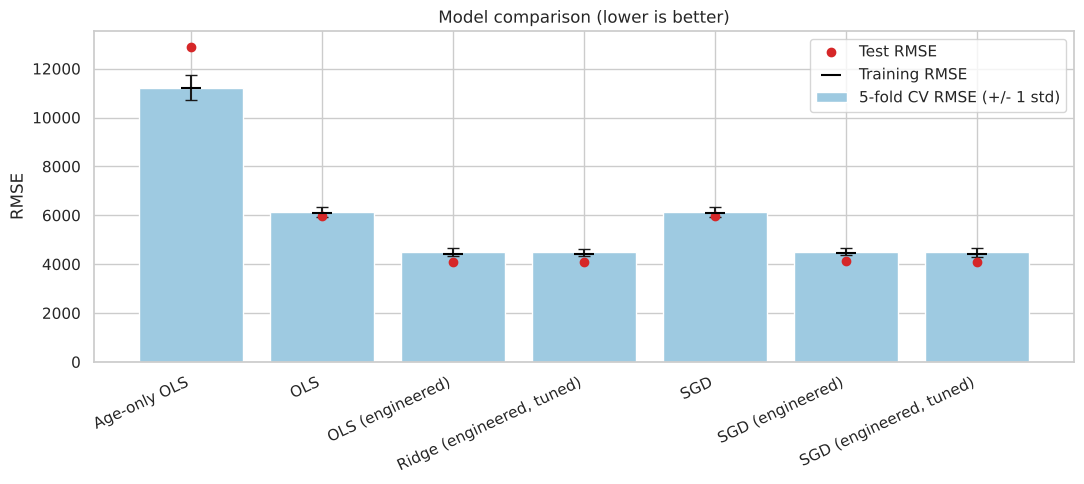

Saved reports/model_comparison.csv


In [13]:
order = SIMPLICITY_ORDER
cv_plot = cv_summary.set_index("Model").loc[order]
test_rmse = comparison[comparison["Dataset"] == "Testing"].set_index("Model").loc[order, "RMSE"]
train_rmse = comparison[comparison["Dataset"] == "Training"].set_index("Model").loc[order, "RMSE"]

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(order))
ax.bar(x, cv_plot["CV_RMSE_mean"], yerr=cv_plot["CV_RMSE_std"], capsize=4, color="#9ecae1", label="5-fold CV RMSE (+/- 1 std)")
ax.scatter(x, test_rmse, color="#d62728", zorder=3, label="Test RMSE")
ax.scatter(x, train_rmse, color="black", marker="_", s=200, zorder=3, label="Training RMSE")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=25, ha="right")
ax.set_ylabel("RMSE"); ax.set_title("Model comparison (lower is better)")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_model_comparison_rmse.png", dpi=150, bbox_inches="tight")
plt.show()

REPORTS_DIR.mkdir(exist_ok=True)
comparison.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)
print("Saved", (REPORTS_DIR / "model_comparison.csv").relative_to(PROJECT_ROOT))

This file is the same one produced by `python -m src.train`.

## Summary

* RMSE, MAE and R-squared were computed with scikit-learn and verified by hand.
* OLS and SGD match on this problem once features are scaled; interactions matter much more than the choice of optimiser.
* Tuning and regularisation gave no meaningful gain beyond the engineered features, so the simplest adequate model was selected by a rule fixed *before* looking at test results.

## Common errors and fixes
| Problem | Cause | Fix |
|---|---|---|
| Choosing the model with the best **test** score | uses the test set for selection | select with CV on training data; test once at the end |
| `mean_squared_error(..., squared=False)` error | the `squared` argument was removed in recent scikit-learn | use `np.sqrt(mean_squared_error(...))` (done in `evaluate.py`) |
| Negative R-squared | model worse than predicting the mean | check scaling, regularisation strength and features |

## Practical task
1. Add `Lasso` (from `sklearn.linear_model`) as another candidate in `get_candidates`. Does it enter the one-SE tied group?
2. Without running code, predict: would the one-SE rule change if the fold standard deviation were halved? Check by editing `select_best_model`.
3. Explain the difference between a model's CV RMSE and its test RMSE and why we report both.

**Next:** notebook 07 - residual analysis, saving the model and making predictions.